In [1]:
import pandas as pd
import warnings

def consolidate_french_regions(file_path="../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21203905_spreadsheet.xlsx"):
    # Suppress openpyxl warnings about default styles
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        xls = pd.ExcelFile(file_path)
        # Sheet 3 contains the "Persons employed" data
        df = pd.read_excel(xls, sheet_name='Sheet 3')
    
    # Extract years from row 7 (index 7)
    years_row = df.iloc[7].values
    years = [str(y) for y in years_row if pd.notna(y) and str(y).isdigit()]
    
    # The actual data starts at index 9
    data = df.iloc[9:, :].copy()
    
    # Identify value columns (they alternate with flag columns in Eurostat format)
    value_cols = [col for i, col in enumerate(df.columns) if i >= 2 and i % 2 == 0]
    
    # Clean up the dataframe
    data_clean = data[[df.columns[0], df.columns[1]] + value_cols].copy()
    data_clean.columns = ['GEO_Code', 'GEO_Label'] + years
    data_clean.replace([':', 'NaN', ''], pd.NA, inplace=True)
    
    # Convert value columns to numeric
    for y in years:
        data_clean[y] = pd.to_numeric(data_clean[y], errors='coerce')
        
    # Filter for just French entities
    france_data = data_clean[data_clean['GEO_Code'].str.startswith('FR', na=False)].copy()

    # Define the mapping: New 13 Regions -> Old NUTS 2 & NUTS 2013/2010 codes
    # 3-letter codes are parent regions, 4-letter codes are sub-regions
    new_region_mapping = {
        "Île-de-France": ["FR1", "FR10"],
        "Centre-Val de Loire": ["FRB", "FRB0", "FR24"],
        "Bourgogne-Franche-Comté": ["FRC", "FRC1", "FRC2", "FR26", "FR43"],
        "Normandie": ["FRD", "FRD1", "FRD2", "FR25", "FR23"],
        "Hauts-de-France": ["FRE", "FRE1", "FRE2", "FR30", "FR22"],
        "Grand Est": ["FRF", "FRF1", "FRF2", "FRF3", "FR42", "FR21", "FR41"],
        "Pays de la Loire": ["FRG", "FRG0", "FR51"],
        "Bretagne": ["FRH", "FRH0", "FR52"],
        "Nouvelle-Aquitaine": ["FRI", "FRI1", "FRI2", "FRI3", "FR61", "FR63", "FR53"],
        "Occitanie": ["FRJ", "FRJ1", "FRJ2", "FR81", "FR62"],
        "Auvergne-Rhône-Alpes": ["FRK", "FRK1", "FRK2", "FR72", "FR71"],
        "Provence-Alpes-Côte d'Azur": ["FRL", "FRL0", "FR82"],
        "Corse": ["FRM", "FRM0", "FR83"]
    }
    
    final_rows = []
    
    # Process the aggregation while avoiding double counting
    for new_region_name, code_list in new_region_mapping.items():
        subset = france_data[france_data['GEO_Code'].isin(code_list)].copy()
        
        parent_codes = [c for c in code_list if len(c) == 3] 
        child_codes = [c for c in code_list if len(c) == 4]  
        
        row_data = {'New_Region': new_region_name}
        
        for year in years:
            val = pd.NA
            
            # Step 1: Check if the parent region already has a consolidated value
            parent_df = subset[subset['GEO_Code'].isin(parent_codes)]
            if not parent_df.empty:
                p_sum = parent_df[year].sum(min_count=1)
                if pd.notna(p_sum):
                    val = p_sum
            
            # Step 2: If the parent is NaN (e.g., historical years), sum up the child sub-regions
            if pd.isna(val):
                child_df = subset[subset['GEO_Code'].isin(child_codes)]
                if not child_df.empty:
                    c_sum = child_df[year].sum(min_count=1)
                    if pd.notna(c_sum):
                        val = c_sum
            
            row_data[year] = val
            
        final_rows.append(row_data)

    # Convert to dataframe and export
    final_df = pd.DataFrame(final_rows)
    
    output_filename = "french_auto_employment_13_regions.xlsx"
    final_df.to_excel(output_filename, index=False)
    
    print(f"Success! Data exported to {output_filename}")
    return final_df

# Execute the function
if __name__ == "__main__":
    df_consolidated = consolidate_french_regions()
    print("\nPreview:")
    print(df_consolidated[['New_Region', '2008', '2012', '2016', '2020']].head(13).to_string(index=False))

Success! Data exported to french_auto_employment_13_regions.xlsx

Preview:
                New_Region 2008      2012      2016      2020
             Île-de-France <NA>  147179.0  127510.0  147947.0
       Centre-Val de Loire <NA>    4116.0    2310.0    4692.0
   Bourgogne-Franche-Comté <NA>    8227.0    8932.0    4842.0
                 Normandie <NA>    4445.0    4447.0    3035.0
           Hauts-de-France <NA>   16528.0   11786.0    6194.0
                 Grand Est <NA>   15203.0   14246.0   11056.0
          Pays de la Loire <NA>   10773.0    9359.0    6924.0
                  Bretagne <NA>    2440.0    2294.0    2141.0
        Nouvelle-Aquitaine <NA>    6101.0    5251.0    3444.0
                 Occitanie <NA>    1002.0    1254.0    1325.0
      Auvergne-Rhône-Alpes <NA>   25555.0   24105.0   34775.0
Provence-Alpes-Côte d'Azur <NA>      <NA>      <NA>     850.0
                     Corse <NA>      <NA>      <NA>      <NA>


In [3]:
df_consolidated.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   New_Region  13 non-null     object
 1   2008        0 non-null      object
 2   2009        0 non-null      object
 3   2010        12 non-null     object
 4   2011        12 non-null     object
 5   2012        11 non-null     object
 6   2013        12 non-null     object
 7   2014        12 non-null     object
 8   2015        11 non-null     object
 9   2016        11 non-null     object
 10  2017        11 non-null     object
 11  2018        11 non-null     object
 12  2019        11 non-null     object
 13  2020        12 non-null     object
dtypes: object(14)
memory usage: 1.6+ KB


In [4]:
df_consolidated.to_excel('/Users/majdshamashan/Downloads/eurostat_consolidated.xlsx', index=False)

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_excel("/Users/majdshamashan/Downloads/eurostat_consolidated.xlsx")
# --- THE FIX: Force all column headers to be strings ---
df.columns = df.columns.astype(str)

# 2. Clean the data: replace dashes/zeroes with NaN and ensure columns are numeric
year_cols = [col for col in df.columns if col.isdigit()]

for col in year_cols:
    # Convert any string dashes to NaN, then convert column to float
    df[col] = pd.to_numeric(df[col].replace(["-", 0, "0"], np.nan), errors='coerce')

# Set the region as the index for easier plotting later
df.set_index('Region', inplace=True)

print("Data loaded and cleaned! Ready to plot.")

Data loaded and cleaned! Ready to plot.


/var/folders/h0/cmm4fsss18l_d3l4lkzj5pxc0000gn/T/ipykernel_33654/1457480431.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = pd.to_numeric(df[col].replace(["-", 0, "0"], np.nan), errors='coerce')


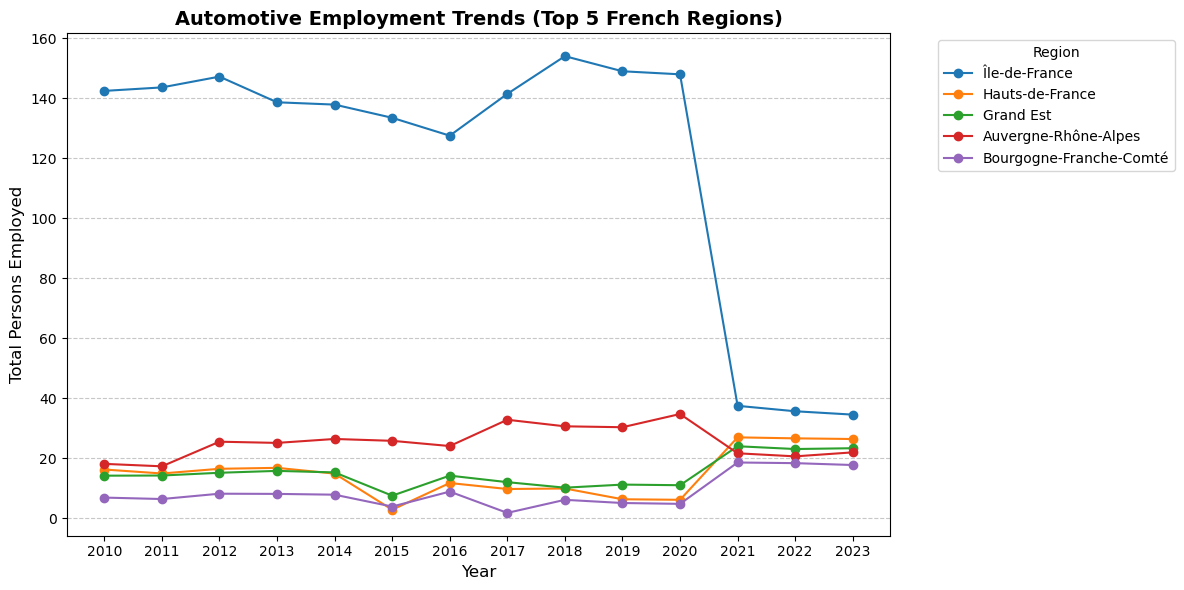

In [13]:
# Isolate the top 5 regions in 2023
top_5_regions = df.sort_values(by='2023', ascending=False).head(5)

plt.figure(figsize=(12, 6))

# Plot each region
for region in top_5_regions.index:
    plt.plot(year_cols, top_5_regions.loc[region, year_cols], marker='o', label=region)

plt.title('Automotive Employment Trends (Top 5 French Regions)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Persons Employed', fontsize=12)
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

/var/folders/h0/cmm4fsss18l_d3l4lkzj5pxc0000gn/T/ipykernel_33654/531619331.py:22: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()




In [14]:
plt.figure(figsize=(10, 8))

# Sort the dataframe by 2023 values for a cascading bar effect
df_2023 = df[['2023']].dropna().sort_values(by='2023', ascending=True)

# Create a horizontal barplot
bars = plt.barh(df_2023.index, df_2023['2023'], color='skyblue', edgecolor='black')

plt.title('Automotive Employment by Region (2023)', fontsize=14, fontweight='bold')
plt.xlabel('Total Persons Employed', fontsize=12)
plt.ylabel('Region', fontsize=12)

# Add the specific data values to the end of each bar
for bar in bars:
    plt.text(bar.get_width() + 500,  # X offset
             bar.get_y() + bar.get_height()/2, # Y center
             f"{int(bar.get_width()):,}", 
             va='center')

# Despine to make it look cleaner
sns.despine()
plt.tight_layout()
plt.show()

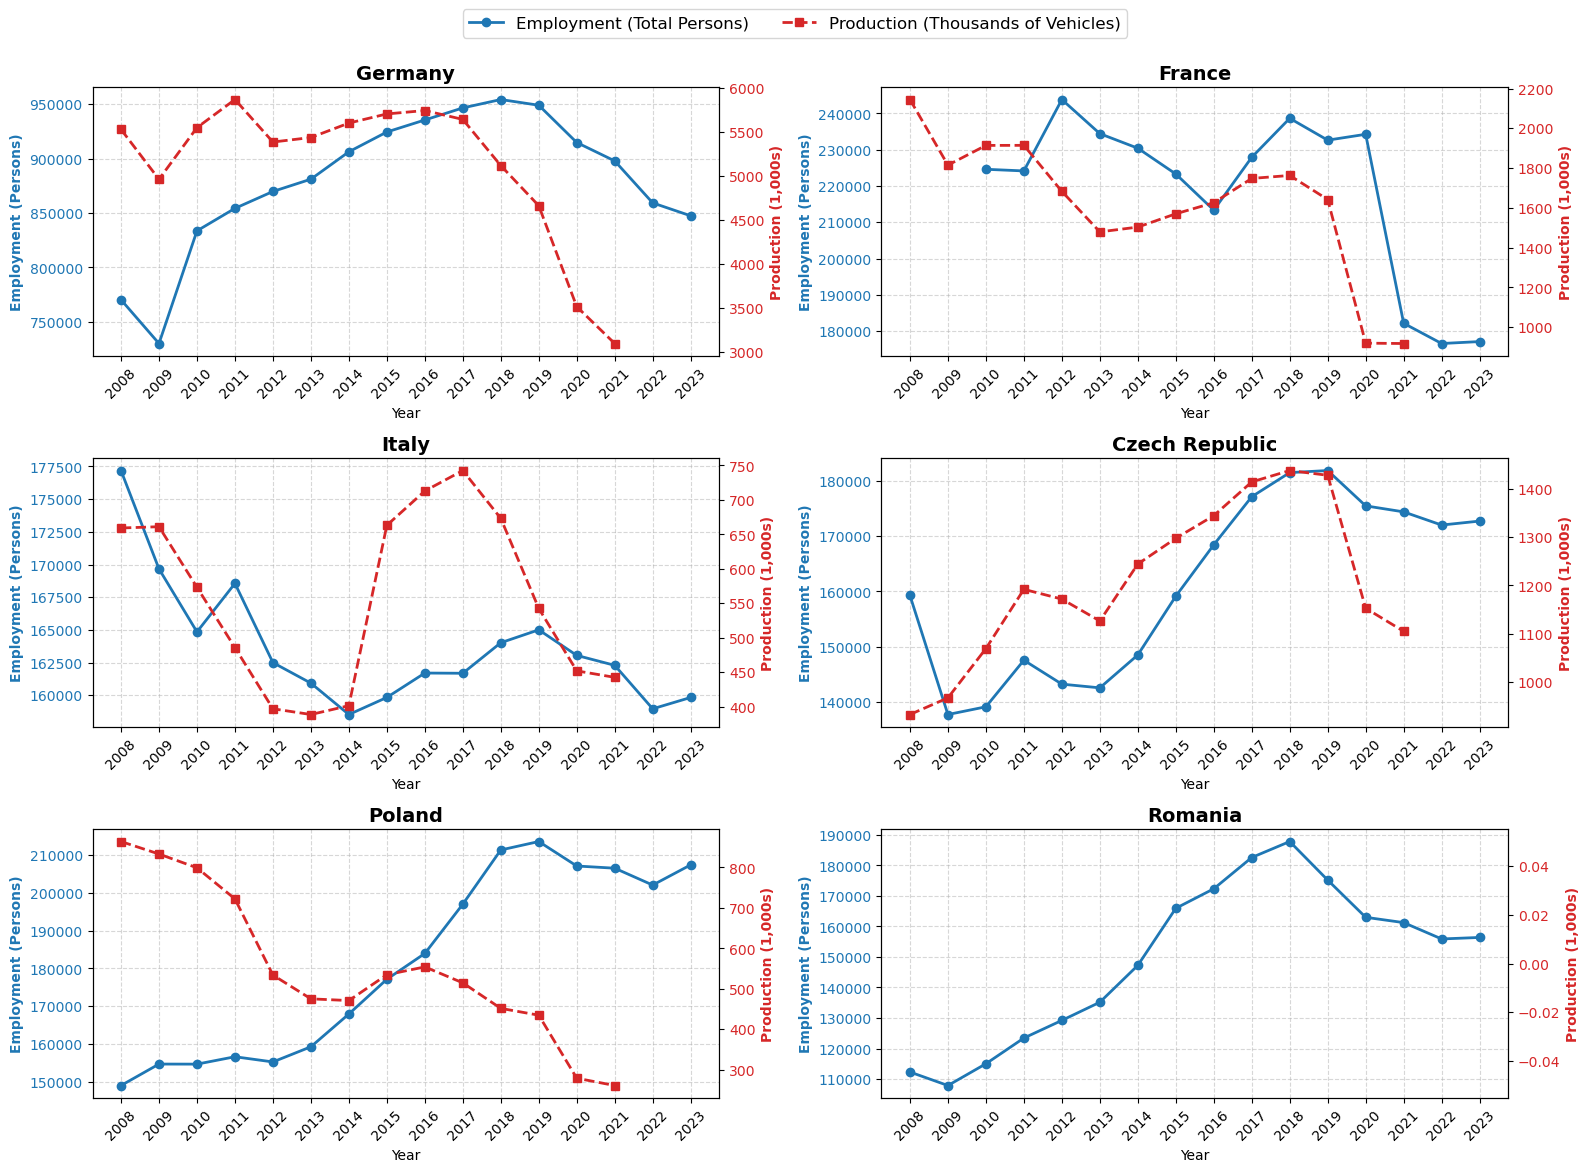

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

def plot_employment_vs_production():
    # Suppress openpyxl default style warnings for cleaner console output
    warnings.simplefilter("ignore")
    
    # --- 1. EUROSTAT EMPLOYMENT DATA (2008-2020) ---
    xls1 = pd.ExcelFile("../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21203905_spreadsheet.xlsx")
    df1 = pd.read_excel(xls1, sheet_name='Sheet 3')
    years1 = [str(y) for y in df1.iloc[7].values if pd.notna(y) and str(y).isdigit()]
    
    d1 = df1.iloc[9:, :].copy()
    val_cols1 = [col for i, col in enumerate(df1.columns) if i >= 2 and i % 2 == 0]
    emp1 = d1[[df1.columns[0], df1.columns[1]] + val_cols1].copy()
    emp1.columns = ['GEO_Code', 'GEO_Label'] + years1
    emp1.replace([':', 'NaN', '', ' ', 'c', 'd', 'u'], np.nan, inplace=True)
    
    for y in years1: 
        emp1[y] = pd.to_numeric(emp1[y], errors='coerce')
    emp1 = emp1[emp1['GEO_Code'].isin(['DE', 'PL', 'FR', 'CZ', 'IT', 'RO'])]

    # --- 2. EUROSTAT EMPLOYMENT DATA (2021-2023) ---
    xls2 = pd.ExcelFile("../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21203869_spreadsheet.xlsx")
    
    # Average per unit (Sheet 1)
    df2_1 = pd.read_excel(xls2, sheet_name='Sheet 1')
    years2 = [str(y) for y in df2_1.iloc[7].values if pd.notna(y) and str(y).isdigit()]
    d2_1 = df2_1.iloc[9:, :].copy()
    val_cols2 = [col for i, col in enumerate(df2_1.columns) if i >= 2 and i % 2 == 0]
    emp2_1 = d2_1[[df2_1.columns[0], df2_1.columns[1]] + val_cols2].copy()
    emp2_1.columns = ['GEO_Code', 'GEO_Label'] + years2
    emp2_1.replace([':', 'NaN', '', ' ', 'c', 'd', 'u'], np.nan, inplace=True)
    for y in years2: 
        emp2_1[y] = pd.to_numeric(emp2_1[y], errors='coerce')

    # Number of units (Sheet 2)
    df2_2 = pd.read_excel(xls2, sheet_name='Sheet 2')
    d2_2 = df2_2.iloc[9:, :].copy()
    emp2_2 = d2_2[[df2_2.columns[0], df2_2.columns[1]] + val_cols2].copy()
    emp2_2.columns = ['GEO_Code', 'GEO_Label'] + years2
    emp2_2.replace([':', 'NaN', '', ' ', 'c', 'd', 'u'], np.nan, inplace=True)
    for y in years2: 
        emp2_2[y] = pd.to_numeric(emp2_2[y], errors='coerce')

    # Multiply to get totals
    emp2 = pd.merge(emp2_1, emp2_2, on=['GEO_Code', 'GEO_Label'], suffixes=('_avg', '_units'))
    for y in years2:
        emp2[y] = emp2[f'{y}_avg'] * emp2[f'{y}_units']
    emp2 = emp2[['GEO_Code', 'GEO_Label'] + years2]
    emp2 = emp2[emp2['GEO_Code'].isin(['DE', 'PL', 'FR', 'CZ', 'IT', 'RO'])]

    # Merge all employment years together
    emp = pd.merge(emp1, emp2.drop(columns=['GEO_Label']), on='GEO_Code', how='left')
    
    # --- 3. PRODUCTION DATA (2008-2021) ---
    xls3 = pd.ExcelFile("../../03_data_raw/exploration_inputs/table_01_23_092922.xlsx")
    prod_raw = pd.read_excel(xls3, sheet_name='1-23')
    
    # Extract and clean headers from row 0
    headers = prod_raw.iloc[0].values
    clean_headers = []
    for h in headers:
        if pd.isna(h):
            clean_headers.append('Country')
        else:
            clean_headers.append(str(h).replace('(R) ', '').replace('(P) ', '').strip())
            
    prod = prod_raw.iloc[2:].copy() # Skip initial header rows
    prod.columns = clean_headers
    
    # Clean up country names (remove trailing footnote letters like 'b' or 'c')
    prod['Country'] = prod['Country'].astype(str).str.strip().str.replace('b$', '', regex=True).str.replace('c$', '', regex=True).str.strip()
    
    country_map = {
        'DE': 'Germany',
        'PL': 'Poland',
        'FR': 'France',
        'CZ': 'Czech Republic',
        'IT': 'Italy',
        'RO': 'Romania'
    }
    
    all_years = [str(y) for y in range(2008, 2024)]
    
    # --- 4. PLOTTING ---
    fig, axes = plt.subplots(3, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    for i, code in enumerate(['DE', 'FR', 'IT', 'CZ', 'PL', 'RO']):
        ax1 = axes[i]
        c_name = country_map[code]
        
        # Extract Employment Data for the loop
        emp_data = emp[emp['GEO_Code'] == code]
        y_emp = []
        for y in all_years:
            if y in emp_data.columns and not emp_data.empty:
                y_emp.append(emp_data.iloc[0][y])
            else:
                y_emp.append(np.nan)
                
        # Extract Production Data for the loop
        prod_c_name = c_name
        if c_name == 'Czech Republic':
            matches = prod[prod['Country'].str.contains('Czech', na=False)]
            if not matches.empty:
                prod_c_name = matches.iloc[0]['Country']
                
        p_data = prod[prod['Country'] == prod_c_name]
        y_prod = []
        for y in all_years:
            if y in p_data.columns and not p_data.empty:
                val = p_data.iloc[0][y]
                if val == 'U' or val == ' ' or pd.isna(val):
                    y_prod.append(np.nan)
                else:
                    y_prod.append(float(val))
            else:
                y_prod.append(np.nan)
                
        years_plot = np.arange(2008, 2024)
        
        # Plot Employment (Left Axis, Blue, Solid Line)
        color1 = '#1f77b4'
        ax1.set_xlabel('Year')
        ax1.set_ylabel('Employment (Persons)', color=color1, fontweight='bold')
        l1, = ax1.plot(years_plot, y_emp, color=color1, marker='o', linewidth=2, label='Employment')
        ax1.tick_params(axis='y', labelcolor=color1)
        ax1.set_xticks(years_plot)
        ax1.set_xticklabels(years_plot, rotation=45)
        ax1.grid(True, linestyle='--', alpha=0.5)
        
        # Plot Production (Right Axis, Red, Dashed Line)
        ax2 = ax1.twinx()  
        color2 = '#d62728'
        ax2.set_ylabel('Production (1,000s)', color=color2, fontweight='bold')
        l2, = ax2.plot(years_plot, y_prod, color=color2, marker='s', linestyle='--', linewidth=2, label='Production')
        ax2.tick_params(axis='y', labelcolor=color2)
        
        ax1.set_title(c_name, fontsize=14, fontweight='bold')
        
    # Global Legend and Layout Adjustments
    fig.legend([l1, l2], ['Employment (Total Persons)', 'Production (Thousands of Vehicles)'], 
               loc='upper center', ncol=2, fontsize=12, bbox_to_anchor=(0.5, 0.98))
    
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    
    # Save and display
    plt.savefig('employment_vs_production.png', dpi=300)
    plt.show()

if __name__ == "__main__":
    plot_employment_vs_production()

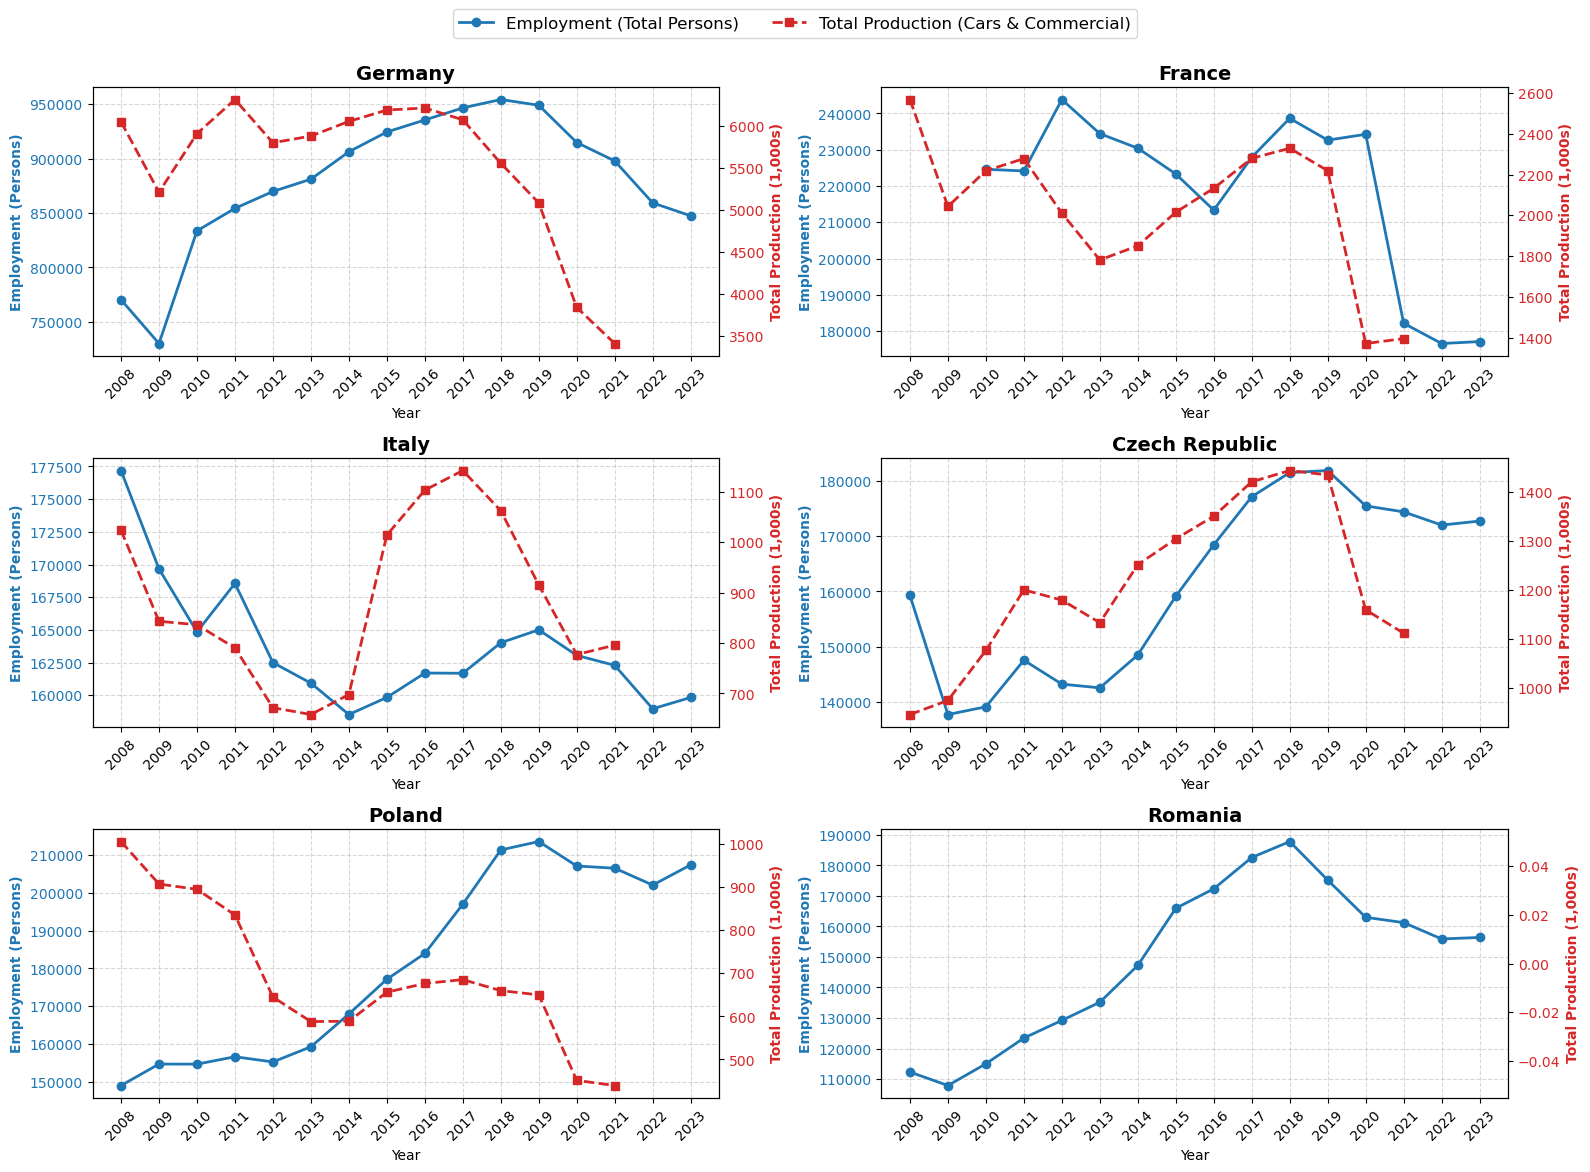

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

def plot_employment_vs_total_production():
    # Suppress openpyxl warnings
    warnings.simplefilter("ignore")
    
    # --- 1. EUROSTAT EMPLOYMENT DATA (2008-2020) ---
    xls1 = pd.ExcelFile("../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21203905_spreadsheet.xlsx")
    df1 = pd.read_excel(xls1, sheet_name='Sheet 3')
    years1 = [str(y) for y in df1.iloc[7].values if pd.notna(y) and str(y).isdigit()]
    
    d1 = df1.iloc[9:, :].copy()
    val_cols1 = [col for i, col in enumerate(df1.columns) if i >= 2 and i % 2 == 0]
    emp1 = d1[[df1.columns[0], df1.columns[1]] + val_cols1].copy()
    emp1.columns = ['GEO_Code', 'GEO_Label'] + years1
    emp1.replace([':', 'NaN', '', ' ', 'c', 'd', 'u'], np.nan, inplace=True)
    
    for y in years1: 
        emp1[y] = pd.to_numeric(emp1[y], errors='coerce')
    emp1 = emp1[emp1['GEO_Code'].isin(['DE', 'PL', 'FR', 'CZ', 'IT', 'RO'])]

    # --- 2. EUROSTAT EMPLOYMENT DATA (2021-2023) ---
    xls2 = pd.ExcelFile("../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21203869_spreadsheet.xlsx")
    
    # Average workers per unit
    df2_1 = pd.read_excel(xls2, sheet_name='Sheet 1')
    years2 = [str(y) for y in df2_1.iloc[7].values if pd.notna(y) and str(y).isdigit()]
    d2_1 = df2_1.iloc[9:, :].copy()
    val_cols2 = [col for i, col in enumerate(df2_1.columns) if i >= 2 and i % 2 == 0]
    emp2_1 = d2_1[[df2_1.columns[0], df2_1.columns[1]] + val_cols2].copy()
    emp2_1.columns = ['GEO_Code', 'GEO_Label'] + years2
    emp2_1.replace([':', 'NaN', '', ' ', 'c', 'd', 'u'], np.nan, inplace=True)
    for y in years2: 
        emp2_1[y] = pd.to_numeric(emp2_1[y], errors='coerce')

    # Total units
    df2_2 = pd.read_excel(xls2, sheet_name='Sheet 2')
    d2_2 = df2_2.iloc[9:, :].copy()
    emp2_2 = d2_2[[df2_2.columns[0], df2_2.columns[1]] + val_cols2].copy()
    emp2_2.columns = ['GEO_Code', 'GEO_Label'] + years2
    emp2_2.replace([':', 'NaN', '', ' ', 'c', 'd', 'u'], np.nan, inplace=True)
    for y in years2: 
        emp2_2[y] = pd.to_numeric(emp2_2[y], errors='coerce')

    # Multiply to get total employment
    emp2 = pd.merge(emp2_1, emp2_2, on=['GEO_Code', 'GEO_Label'], suffixes=('_avg', '_units'))
    for y in years2:
        emp2[y] = emp2[f'{y}_avg'] * emp2[f'{y}_units']
    emp2 = emp2[['GEO_Code', 'GEO_Label'] + years2]
    emp2 = emp2[emp2['GEO_Code'].isin(['DE', 'PL', 'FR', 'CZ', 'IT', 'RO'])]

    # Merge historical and current employment
    emp = pd.merge(emp1, emp2.drop(columns=['GEO_Label']), on='GEO_Code', how='left')
    
    # --- 3. PRODUCTION DATA (TOTAL PASSENGER + COMMERCIAL) ---
    xls3 = pd.ExcelFile("../../03_data_raw/exploration_inputs/table_01_23_092922.xlsx")
    prod_raw = pd.read_excel(xls3, sheet_name='1-23')
    
    headers = prod_raw.iloc[0].values
    clean_headers = []
    for h in headers:
        if pd.isna(h):
            clean_headers.append('Country')
        else:
            clean_headers.append(str(h).replace('(R) ', '').replace('(P) ', '').strip())
            
    # THE FIX: Slice the dataframe specifically to the "Total passenger & commercial" block
    prod = prod_raw.iloc[72:110].copy()
    prod.columns = clean_headers
    prod['Country'] = prod['Country'].astype(str).str.strip()
    
    country_map = {
        'DE': 'Germany',
        'PL': 'Poland',
        'FR': 'France',
        'CZ': 'Czech Republic',
        'IT': 'Italy',
        'RO': 'Romania'
    }
    
    all_years = [str(y) for y in range(2008, 2024)]
    
    # --- 4. PLOTTING ---
    fig, axes = plt.subplots(3, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    for i, code in enumerate(['DE', 'FR', 'IT', 'CZ', 'PL', 'RO']):
        ax1 = axes[i]
        c_name = country_map[code]
        
        # Employment
        emp_data = emp[emp['GEO_Code'] == code]
        y_emp = []
        for y in all_years:
            if y in emp_data.columns and not emp_data.empty:
                y_emp.append(emp_data.iloc[0][y])
            else:
                y_emp.append(np.nan)
                
        # Total Production (Cars + Commercial)
        matches = prod[prod['Country'].str.contains(c_name.split()[0], na=False, case=False)]
        y_prod = []
        if not matches.empty:
            p_data = matches.iloc[0]
            for y in all_years:
                if y in prod.columns:
                    val = p_data[y]
                    if val == 'U' or val == ' ' or pd.isna(val):
                        y_prod.append(np.nan)
                    else:
                        try:
                            y_prod.append(float(val))
                        except:
                            y_prod.append(np.nan)
                else:
                    y_prod.append(np.nan)
        else:
            y_prod = [np.nan] * len(all_years)
                
        years_plot = np.arange(2008, 2024)
        
        color1 = '#1f77b4'
        ax1.set_xlabel('Year')
        ax1.set_ylabel('Employment (Persons)', color=color1, fontweight='bold')
        l1, = ax1.plot(years_plot, y_emp, color=color1, marker='o', linewidth=2, label='Employment')
        ax1.tick_params(axis='y', labelcolor=color1)
        ax1.set_xticks(years_plot)
        ax1.set_xticklabels(years_plot, rotation=45)
        ax1.grid(True, linestyle='--', alpha=0.5)
        
        ax2 = ax1.twinx()  
        color2 = '#d62728'
        ax2.set_ylabel('Total Production (1,000s)', color=color2, fontweight='bold')
        l2, = ax2.plot(years_plot, y_prod, color=color2, marker='s', linestyle='--', linewidth=2, label='Total Production')
        ax2.tick_params(axis='y', labelcolor=color2)
        
        ax1.set_title(c_name, fontsize=14, fontweight='bold')
        
    fig.legend([l1, l2], ['Employment (Total Persons)', 'Total Production (Cars & Commercial)'], 
               loc='upper center', ncol=2, fontsize=12, bbox_to_anchor=(0.5, 0.98))
    
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig('employment_vs_total_production.png', dpi=300)
    plt.show()

# Run the function
if __name__ == "__main__":
    plot_employment_vs_total_production()

In [23]:
import pandas as pd

def process_eurostat_csv(filepath):
    # 1. Read CSV, skipping the first 8 lines of metadata
    df = pd.read_excel(filepath, sheet_name='employment', skiprows=8, header=None)
    
    # 2. Extract headers from the first two rows 
    # (Row 0 has the Years, Row 1 has the GEO labels)
    years_row = df.iloc[0].fillna('')
    
    cols = ['GEO (Codes)', 'GEO (Labels)']
    years = []
    
    # Iterate through the columns to assign Year_Value and Year_Flag
    for i in range(2, len(df.columns)):
        if i % 2 == 0:
            year = str(years_row[i]).strip()
            cols.append(f"{year}_Value")
            years.append(year)
        else:
            cols.append(f"{years[-1]}_Flag")
            
    df.columns = cols
    
    # Drop the first two rows (which contained the raw headers)
    df = df.drop([0, 1]).reset_index(drop=True)
    
    # 3. Melt the values into long format
    value_cols = [c for c in df.columns if c.endswith('_Value')]
    df_values = df.melt(id_vars=['GEO (Codes)', 'GEO (Labels)'], value_vars=value_cols, 
                        var_name='Year', value_name='Value')
    df_values['Year'] = df_values['Year'].str.replace('_Value', '')
    
    # 4. Melt the flags into long format
    flag_cols = [c for c in df.columns if c.endswith('_Flag')]
    df_flags = df.melt(id_vars=['GEO (Codes)', 'GEO (Labels)'], value_vars=flag_cols, 
                       var_name='Year', value_name='Flag')
    df_flags['Year'] = df_flags['Year'].str.replace('_Flag', '')
    
    # 5. Merge the values and flags back together
    df_long = pd.merge(df_values, df_flags, on=['GEO (Codes)', 'GEO (Labels)', 'Year'])
    
    return df_long

# File paths
file_old_emp = '../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21357611_spreadsheet.xlsx'
file_new_emp = '../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21357526_spreadsheet.xlsx'

# Process both files
df_old = process_eurostat_csv(file_old_emp)
df_new = process_eurostat_csv(file_new_emp)

# Combine them into a single timeline
df_merged = pd.concat([df_old, df_new], ignore_index=True)

# Convert Year to integer for proper sorting
df_merged['Year'] = df_merged['Year'].astype(int)

# Sort by region and year 
df_merged = df_merged.sort_values(by=['GEO (Codes)', 'Year']).reset_index(drop=True)

# Optional: filter out invalid/empty GEO codes if necessary
df_merged = df_merged[df_merged['GEO (Codes)'] != ':']

# Save the final dataset
output_file = '../../03_data_raw/exploration_inputs/merged_country_employment.xlsx'
df_merged.to_excel(output_file, index=False)

print(df_merged.head(10))
print(f"Dataset successfully merged and saved to {output_file}")

   GEO (Codes) GEO (Labels)  Year  Value Flag
16          AT      Austria  2008  33553  NaN
17          AT      Austria  2009  30337  NaN
18          AT      Austria  2010  29158  NaN
19          AT      Austria  2011  30572  NaN
20          AT      Austria  2012  31675  NaN
21          AT      Austria  2013  30226  NaN
22          AT      Austria  2014  30633  NaN
23          AT      Austria  2015  30738  NaN
24          AT      Austria  2016  31813  NaN
25          AT      Austria  2017  33001  NaN
Dataset successfully merged and saved to /Users/majdshamashan/Desktop/CIRED stage/datasets/Eurostat/eurostat_2/merged_country_employment.xlsx
